In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Iris.csv")
print("Dataset shape:", df.shape)
print("Categorical columns:", df.select_dtypes(exclude=np.number).columns.tolist())
print("Numeric columns:", df.select_dtypes(include=np.number).columns.tolist())

Dataset shape: (150, 6)
Categorical columns: ['Species']
Numeric columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']


In [3]:
num_col = "SepalLengthCm"
stratify_col = "Species"
cluster_col = "Species"

# Drop rows missing sampling columns
df = df.dropna(subset=[num_col, stratify_col, cluster_col]).reset_index(drop=True)

N = len(df)
n = max(1, int(0.20 * N))
population_mean = df[num_col].mean()
print(f"Population size N={N}, sample size n={n}, population mean of '{num_col}'={population_mean:.4f}")

Population size N=150, sample size n=30, population mean of 'SepalLengthCm'=5.8433


In [4]:
srs_sample = df.sample(n=n, random_state=42)
print("Simple Random Sample size:", len(srs_sample))
print(srs_sample.head())

Simple Random Sample size: 30
      Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  \
73    74            6.1           2.8            4.7           1.2   
18    19            5.7           3.8            1.7           0.3   
118  119            7.7           2.6            6.9           2.3   
78    79            6.0           2.9            4.5           1.5   
76    77            6.8           2.8            4.8           1.4   

             Species  
73   Iris-versicolor  
18       Iris-setosa  
118   Iris-virginica  
78   Iris-versicolor  
76   Iris-versicolor  


Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


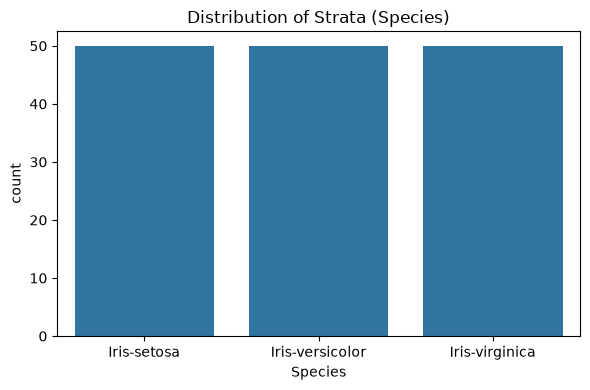

Stratified sample size: 30
                 Population %  Sample %
Species                                
Iris-setosa             33.33     33.33
Iris-versicolor         33.33     33.33
Iris-virginica          33.33     33.33


In [5]:
print(df[stratify_col].value_counts())
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=stratify_col)
plt.title(f"Distribution of Strata ({stratify_col})")
plt.tight_layout()
plt.show()

# Proportional stratified sampling
parts = []
for grp, g in df.groupby(stratify_col, sort=False):
    k = max(1, round(len(g) * n / N))
    parts.append(g.sample(n=k, random_state=42))
strat_sample = pd.concat(parts).reset_index(drop=True)
print("Stratified sample size:", len(strat_sample))

strat_prop = pd.DataFrame({
    "Population %": df[stratify_col].value_counts(normalize=True) * 100,
    "Sample %": strat_sample[stratify_col].value_counts(normalize=True) * 100
}).round(2)
print(strat_prop)

In [6]:
clusters = df[cluster_col].dropna().unique()
k = max(1, int(0.30 * len(clusters)))
rng = np.random.default_rng(42)
selected = rng.choice(clusters, size=k, replace=False)
print(f"Total clusters: {len(clusters)} | Selected clusters: {list(selected)}")

cluster_sample = df[df[cluster_col].isin(selected)].copy()
print("Cluster sample size:", len(cluster_sample))

Total clusters: 3 | Selected clusters: ['Iris-setosa']
Cluster sample size: 50


               Sample Size  Sample Mean  Difference from Population Mean
Simple Random           30        5.980                            0.137
Stratified              30        5.820                           -0.023
Cluster                 50        5.006                           -0.837


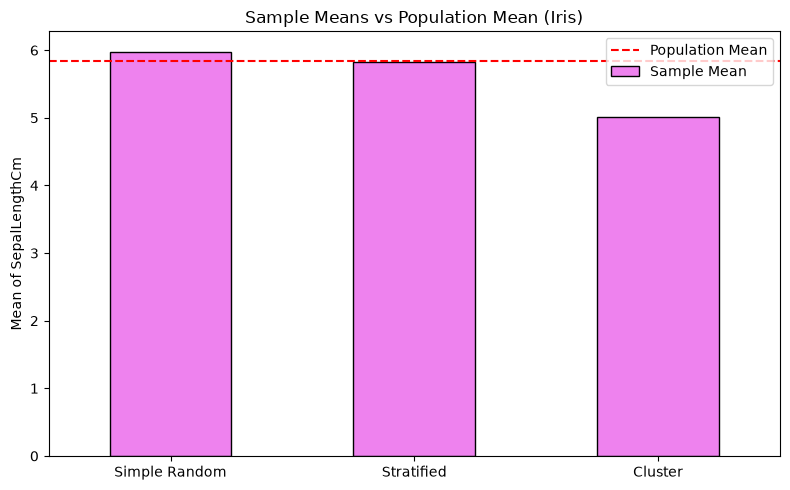

In [7]:
samples = {
    "Simple Random": srs_sample,
    "Stratified": strat_sample,
    "Cluster": cluster_sample
}

comparison = pd.DataFrame({
    "Sample Size": [len(s) for s in samples.values()],
    "Sample Mean": [s[num_col].mean() for s in samples.values()]
}, index=samples.keys())

comparison["Difference from Population Mean"] = comparison["Sample Mean"] - population_mean
print(comparison.round(3))

plt.figure(figsize=(8, 5))
comparison["Sample Mean"].plot(kind="bar", rot=0, color="violet", edgecolor="black")
plt.axhline(population_mean, color="red", linestyle="--", label="Population Mean")
plt.ylabel(f"Mean of {num_col}")
plt.title("Sample Means vs Population Mean (Iris)")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
srs_sample.to_csv("SRS_sample.csv", index=False)
strat_sample.to_csv("Stratified_sample.csv", index=False)
cluster_sample.to_csv("Cluster_sample.csv", index=False)
print("Saved sampling datasets to CSV files.")

Saved sampling datasets to CSV files.
